# Cookie Cats A/B Test — Retention Analysis
**Business question.** Cookie Cats moved its first progression gate from level 30 to level 40. Does the later gate change player retention? Retention drives lifetime value, so a gate change that lowers Day-7 retention can be costly even if short-term engagement looks similar.

**Sign convention:** effect = `gate_40 − gate_30`, in percentage points (pp).

## Research questions
1. Did Day-1 retention differ? 2. Did Day-7 retention differ? 3. How large is the effect? 4. How uncertain is it? 5. Is there an allocation anomaly? 6. What must be known before deciding?

## Reproducible setup
Run from anywhere inside the repository; the project root is discovered, no absolute paths.

In [1]:
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(root / "src"))
import numpy as np, pandas as pd, scipy
import matplotlib.pyplot as plt
from cookie_cat import data, contract, stats, sqlchecks, decision
print("root:", root.name, "| pandas", pd.__version__, "| scipy", scipy.__version__)

root: cookie-cat | pandas 2.3.3 | scipy 1.17.1


## Data loading and provenance

In [2]:
raw = data.load_raw()
prov = data.provenance()
print("shape:", raw.shape); print(raw.dtypes.to_string()); print("sha256:", prov.sha256, "| bytes:", prov.size_bytes)
raw.head()

shape: (90189, 5)
userid             int64
version           object
sum_gamerounds     int64
retention_1         bool
retention_7         bool
sha256: 5ab54d761fbddcd50de7b88e4eaf7837cba4569474f50c043a4d17ee342c46bd | bytes: 2707297


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [3]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
userid,90189.0,4.998412e+06,2.883286e+06,116.0,2512230.0,4995815.0,7496452.0,9999861.0
sum_gamerounds,90189.0,5.187246e+01,1.950509e+02,0.0,5.0,16.0,51.0,49854.0


## Data-quality audit
Every rule is severity-classified; nothing is dropped or silently coerced.

In [4]:
audit = contract.audit(raw)
pd.DataFrame(audit["rules"])[["rule_id","description","severity","status","observed","affected"]]

,rule_id,description,severity,status,observed,affected
0,C001,Required columns present,error,pass,all present,0
1,C002,Dataset is not empty,error,pass,90189 rows,0
2,C003,userid has no missing values,error,pass,0 missing,0
3,C004,userid is unique,error,pass,0 rows share an id,0
4,C005,version is one of the known arms,error,pass,0 unexpected,0
5,C006,Both arms present,error,pass,2 arms,0
6,C007,sum_gamerounds is numeric,error,pass,0 non-numeric,0
7,C008,sum_gamerounds is non-negative,error,pass,0 negative,0
8,C009,retention_1 is boolean-like,error,pass,0 invalid,0
9,C010,retention_7 is boolean-like,error,pass,0 invalid,0


In [5]:
print("Blocked:", audit["blocked"], "| failing by severity:", audit["counts"])
df = contract.to_analysis_frame(raw)

Blocked: False | failing by severity: {'error': 0, 'warning': 1, 'info': 0}


Rule **C013** is a genuine warning: at least one player has an extreme round count. It is kept in the analysis (assignment-based, no exclusions) and motivates the rank-based engagement test below.

## Exploratory analysis

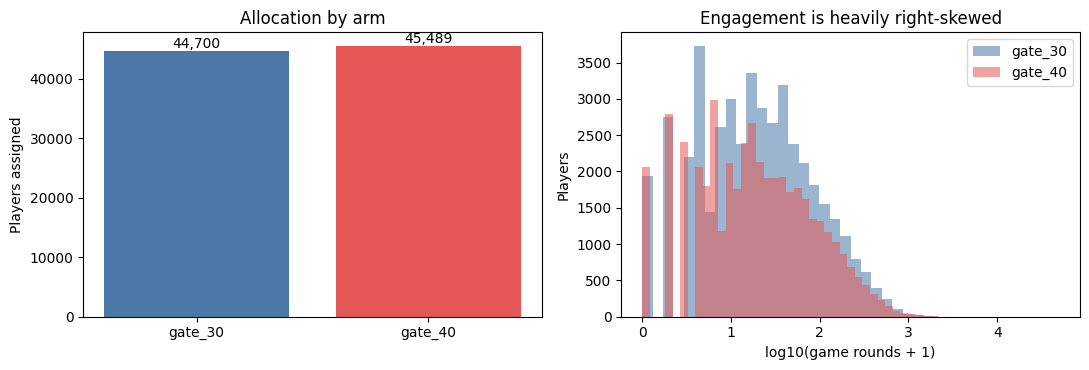

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
counts = df.version.value_counts().reindex(["gate_30","gate_40"])
ax[0].bar(counts.index, counts.values, color=["#4c78a8","#e45756"]); ax[0].set_ylabel("Players assigned"); ax[0].set_title("Allocation by arm")
for i, v in enumerate(counts.values): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
for g, c in (("gate_30","#4c78a8"),("gate_40","#e45756")):
    ax[1].hist(np.log10(df.loc[df.version==g,"sum_gamerounds"]+1), bins=40, alpha=.55, label=g, color=c)
ax[1].set_xlabel("log10(game rounds + 1)"); ax[1].set_ylabel("Players"); ax[1].set_title("Engagement is heavily right-skewed"); ax[1].legend()
plt.tight_layout(); plt.show()

*Figure: left, players per arm; right, log-scaled game rounds. The skew means means are dominated by a few heavy players.*

## Retention calculations and treatment effects

In [7]:
rows = []
for o in ("retention_1","retention_7"):
    e = stats.retention_effect(df, o)
    rows.append({"outcome":o, "n_30":e["n_control"], "ret_30":e["retained_control"], "rate_30_%":100*e["rate_control"],
                 "n_40":e["n_treatment"], "ret_40":e["retained_treatment"], "rate_40_%":100*e["rate_treatment"],
                 "diff_pp":e["diff_pp"], "rel_%":e["relative_change_pct"], "CI_newcombe_pp":tuple(round(x,3) for x in e["ci_newcombe_pp"]),
                 "z":e["z"], "p":e["p_value"]})
effects = pd.DataFrame(rows); effects

,outcome,n_30,ret_30,rate_30_%,n_40,ret_40,rate_40_%,diff_pp,rel_%,CI_newcombe_pp,z,p
0,retention_1,44700,20034,44.818792,45489,20119,44.228275,-0.590517,-1.317566,"(-1.239, 0.058)",-1.784086,0.074410
1,retention_7,44700,8502,19.020134,45489,8279,18.200004,-0.820130,-4.311903,"(-1.328, -0.312)",-3.164359,0.001554


Holm-adjusted p (family: Day-1 & Day-7): {'retention_7': 0.003108499951228658, 'retention_1': 0.07440965529691913}


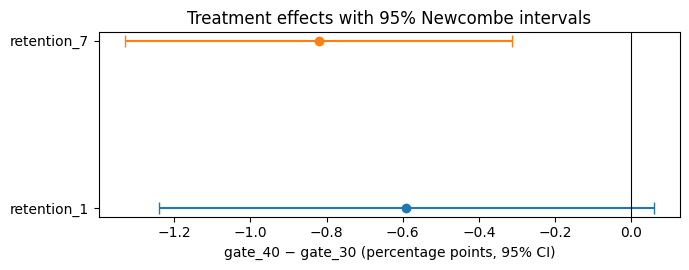

In [8]:
eff = {o: stats.retention_effect(df, o) for o in ("retention_1","retention_7")}
holm = stats.holm({o: e["p_value"] for o, e in eff.items()})   # family = {Day-1, Day-7}
print("Holm-adjusted p (family: Day-1 & Day-7):", holm)
fig, ax = plt.subplots(figsize=(7, 2.8))
for i, (o, e) in enumerate(eff.items()):
    ax.errorbar(e["diff_pp"], i, xerr=[[e["diff_pp"]-e["ci_newcombe_pp"][0]],[e["ci_newcombe_pp"][1]-e["diff_pp"]]], fmt="o", capsize=4)
ax.axvline(0, color="k", lw=.8); ax.set_yticks([0,1]); ax.set_yticklabels(eff.keys()); ax.set_xlabel("gate_40 − gate_30 (percentage points, 95% CI)")
ax.set_title("Treatment effects with 95% Newcombe intervals"); plt.tight_layout(); plt.show()

**Method note.** The primary interval is Newcombe–Wilson; the reference Wald interval is reported by the engine as `ci_wald_pp`. At these sample sizes they agree to ~4 decimals, so differences from earlier reports are not material.

In [9]:
e7 = eff["retention_7"]; print("Newcombe:", [round(x,4) for x in e7["ci_newcombe_pp"]], "| Wald:", [round(x,4) for x in e7["ci_wald_pp"]])

Newcombe: [-1.3282, -0.3121] | Wald: [np.float64(-1.3282), np.float64(-0.3121)]


## SRM investigation
The dataset does not state the planned allocation. **50/50 is an assumption**, made explicit below.

In [10]:
obs = df.version.value_counts().to_dict()
res = {}
for alpha in (0.05, 0.001):
    r = stats.srm(obs, {"gate_30":.5,"gate_40":.5}, alpha=alpha); res[alpha] = r
print("chi2 = %.4f, dof = %d, p = %.6f" % (r["chi2"], r["dof"], r["p_value"]))
for a, r in res.items(): print(f"alpha={a}: warning={r['warning']}")

chi2 = 6.9024, dof = 1, p = 0.008608
alpha=0.05: warning=True
alpha=0.001: warning=False


**Interpretation.** p ≈ 0.0086 flags a mismatch at α = 0.05 but **not** at the stricter α = 0.001 that many experimentation platforms use. So whether this is a "warning" is itself threshold-dependent. Even when flagged, SRM is a symptom, not a diagnosis: resolving it needs the planned allocation and assignment/logging records, which are not in this dataset.

## Engagement analysis

In [11]:
eng = stats.engagement(df); eng

{'mann_whitney_u': 1009027049.5,
 'p_value': 0.05020880772044255,
 'prob_superiority_treatment': 0.49623671809341224,
 'median_control': 17.0,
 'median_treatment': 16.0,
 'mean_control': 52.45626398210291,
 'mean_treatment': 51.29877552814966,
 'note': 'Tests stochastic ordering of the distributions, not a difference in medians. Ties handled by mid-ranks.'}

Mann–Whitney tests whether one distribution tends to produce larger values (stochastic ordering), **not** a difference in medians. Ties are handled with mid-ranks; zeros stay in the sample. The result sits right at p ≈ 0.05, so it is weak evidence either way.

## Sensitivity: evidence vs. decision threshold

In [12]:
rows = []
for blocks in (True, False):
    for imp, loss in [(0.5,0.5),(0.5,1.0),(1.0,0.5)]:
        d = decision.decide(e7, res[0.05]["warning"], decision.Policy(imp, loss, blocks))
        rows.append({"integrity_blocks":blocks,"min_improve_pp":imp,"max_loss_pp":loss,"action":d["action"],"diff_pp":d["invariants"]["diff_pp"],"p":d["invariants"]["p_value"]})
pd.DataFrame(rows)

,integrity_blocks,min_improve_pp,max_loss_pp,action,diff_pp,p
0,True,0.5,0.5,HOLD / INVESTIGATE,-0.82013,0.001554
1,True,0.5,1.0,HOLD / INVESTIGATE,-0.82013,0.001554
2,True,1.0,0.5,HOLD / INVESTIGATE,-0.82013,0.001554
3,False,0.5,0.5,REJECT,-0.82013,0.001554
4,False,0.5,1.0,HOLD / INVESTIGATE,-0.82013,0.001554
5,False,1.0,0.5,REJECT,-0.82013,0.001554


In [13]:
# Invariant: policy changes never change measured statistics.
inv = {tuple(r["diff_pp"] for _ in [0]) + (r["p"],) for r in rows}; assert len(inv) == 1; print("Measured statistics identical across all policies:", inv)

Measured statistics identical across all policies: {(-0.8201298315205913, 0.001554249975614329)}


Policies change the **action**, never the **evidence**. The SRM block is the decisive lever here: with integrity unresolved the action is HOLD; if the allocation were confirmed as planned, the same evidence would support REJECT under a tolerance of ≤ 0.82 pp.

In [14]:
final = decision.decide(e7, res[0.05]["warning"], decision.Policy())
print(final["action"]); [print("-", r) for r in final["reasons"]]

HOLD / INVESTIGATE
- Unresolved integrity warning (sample-ratio) blocks a definitive recommendation under this policy.
- Absent the integrity block the evidence would support REJECT.


[None, None]

## Product recommendation
Provisional **HOLD / INVESTIGATE**: Day-7 retention is lower at gate 40 by about 0.82 pp (CI ≈ −1.33 to −0.31, p ≈ 0.0016) but the SRM flag leaves experiment integrity unresolved. Confirm the planned allocation and assignment logs; if clean, the evidence favours not rolling out gate 40.

## Limitations
- No experiment-design metadata (planned split, dates, randomisation unit, exposure logs).
- Retention flags are as recorded; definitions of Day-1/Day-7 are not documented in the file.
- Pooled z-test assumes independent users; no clustering is available to check.
- SRM result is conditional on the assumed 50/50 split and on α.
- Observational summaries of an assigned experiment support causal claims only if randomisation held.
- Differences from earlier baseline: **none** — all reported figures reproduce (see tests).

## Reproducibility
```
pip install -e .
jupyter nbconvert --to notebook --execute notebooks/01_cookie_cats_retention_analysis.ipynb
```
Dataset: `data/raw/cookie_cats.csv` (fetch with `python scripts/download_data.py`; SHA-256 printed above).